# Symulacja magazynu Kiva: etap z 23.11.2026

**Pytanie projektu:** jak rozmieszczenie produktów i sposób sterowania robotami wpływają na czas
realizacji zamówień w magazynie, w którym roboty przywożą regały do stanowisk kompletacji
(jak Kiva w Amazonie).

**Model:** agentowy (Mesa) z planowaniem zdarzeń dyskretnych, trasy A* z rezerwacją pól,
zamówienia generowane z danych Olist (kalibracja na 2017, walidacja na 2018), parametry robota
z publikacji o Kiva. Schemat przepływu zamówienia: dodatek B.

**Plan:**
1. Co zrobiliśmy od ostatniego spotkania
2. Zakleszczenia: przed i po regułach ruchu
3. Wyniki porównań: rozmieszczenie, liczba robotów, przydział zadań, układy magazynu
4. Czy reguły ruchu się opłacają
5. Kalibracja i walidacja: parametry robota, dane Olist, teoria kolejek
6. Wnioski i co dalej
7. Dodatki: stan scenariuszy, przepływ zamówienia w modelu

Wyniki porównań są **przykładowe**: przebiegi po 4 h od poniedziałku 8:00, 3–5 seedów.
Pełne liczenie (całe doby, więcej seedów) robi runner scenariuszy.

## 1. Co zrobiliśmy od ostatniego spotkania

| Zmiana | Co daje |
| --- | --- |
| Nowa wizualizacja (plan SVG, statystyki i zamówienia na żywo) | widać roboty, baterie, kolejki, czasy realizacji w trakcie przebiegu |
| Układy magazynu z plików JSON | 5 hal do porównania, w tym hala w kształcie L i hala z szerokimi alejkami |
| Poprawki modelu z audytu | strategia „najbliższe wolne miejsce” działa, symulacja liczy się ~5× szybciej, wykrywanie livelocka, poprawny czas kolejki |
| Zapis przebiegów i notatnik porównań | porównania bez GUI, równolegle, z przedziałami ufności |
| **Reguły ruchu** | zakleszczenia spadły z 47% do 1,6% przebiegów, więc porównania przy dużym ruchu są możliwe |
| Walidacja z teorią kolejek | przechodzi do końca, pokazała koszt reguł ruchu przy stanowisku |

Skala obciążenia: **×1** to zwykły dzień (Olist ×10, ok. 40–90 zamówień/h), **×5** wzmożony ruch,
**×9,5** Black Friday (stosunek szczytu do zwykłego dnia w danych z 2017).

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd()
if not (ROOT / "src").is_dir():
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import matplotlib
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.experiments.build import LAYOUTS, olist_stats
from src.experiments.compare import run_grid, summary
from src.plotting.style import CATEGORICAL, INK_SECONDARY, style

style()
OUT = ROOT / "output" / "porownania"
JOBS = 8  # procesy równolegle; zmniejsz na słabszym komputerze
pd.set_option("display.precision", 1)
assert olist_stats() is not None, "Brak danych Olist: uv run data/download_olist.py"

LOAD = {1.0: "zwykły dzień ×1", 5.0: "wzmożony ×5", 9.5: "Black Friday ×9,5"}


def bars(ax, table, group, series, metric, labels=None, colors=None):
    """Grouped bars with 95% intervals: one group per value of ``group``."""
    groups = list(dict.fromkeys(table[group]))
    names = list(dict.fromkeys(table[series]))
    width = 0.8 / len(names)
    for i, name in enumerate(names):
        part = table[table[series] == name].set_index(group).reindex(groups)
        x = np.arange(len(groups)) + (i - (len(names) - 1) / 2) * width
        ax.bar(x, part[metric], width, yerr=part[metric + "_ci"], capsize=3,
               color=(colors or CATEGORICAL)[i], label=(labels or {}).get(name, name))
    ax.set_xticks(np.arange(len(groups)), [(LOAD if group == "volume" else {}).get(g, g) for g in groups])
    ax.grid(axis="x", visible=False)

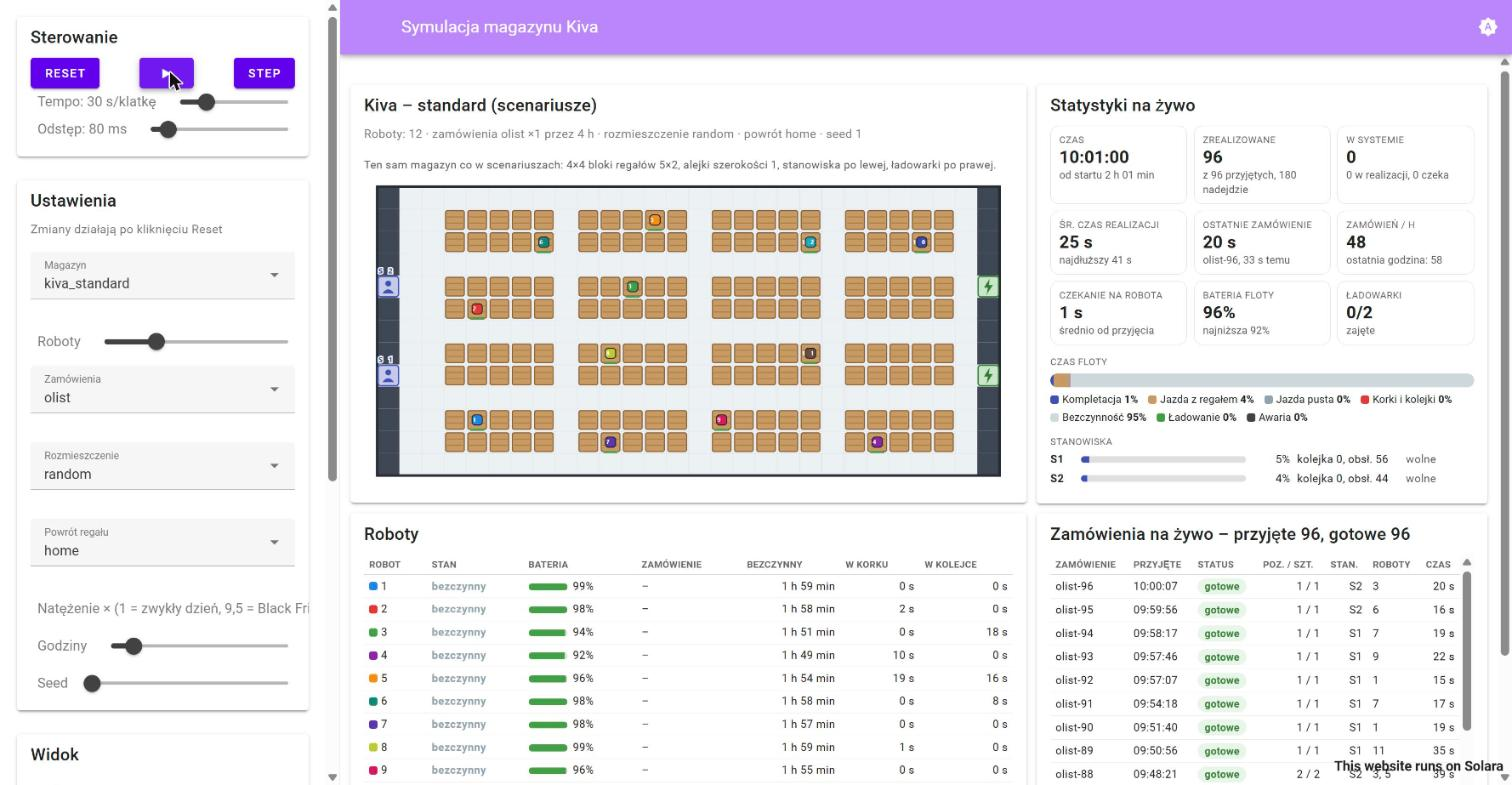

In [2]:
from IPython.display import Image, display

display(Image(filename=str(ROOT / "notebooks" / "img" / "wizualizacja.jpg"), width=1100))

*Wizualizacja (`make visual`): 12 robotów, zwykły dzień, godzina 10:00. Bezczynne roboty stoją
pod regałami (nowa reguła), po prawej statystyki na żywo, na dole roboty i lista zamówień.*

## 2. Zakleszczenia: przed i po regułach ruchu

Wcześniej roboty blokowały się w alejkach szerokości jednego pola (czołowe spotkania, kolejka
zatykająca wyjazd ze stanowiska). Teraz działają reguły ruchu (`TrafficParams`):
- puste roboty jeżdżą pod regałami, jak w Kiva;
- alejki mają kierunki, jazda pod prąd jest droższa;
- najwyżej 3 roboty jadą do jednego stanowiska;
- wolne pole przed zajętym stanowiskiem;
- omijanie stojących robotów;
- zjazd z ładowarki;
- zamówienie idzie do stanowiska najbliższego regałowi.

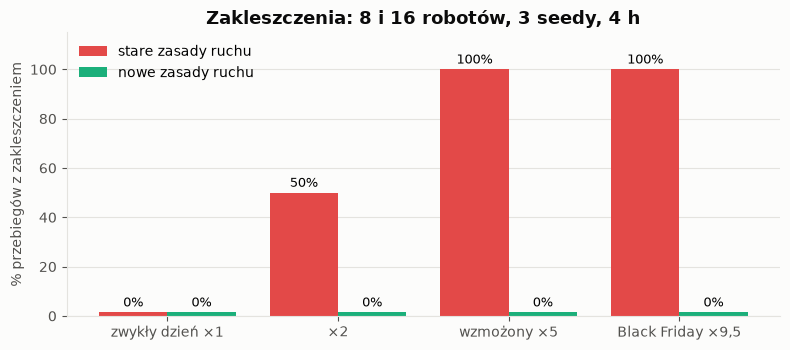

In [3]:
specs = [dict(num_robots=r, volume=v, seed=s, traffic=t)
         for t in ("old", "new") for r in (8, 16) for v in (1.0, 2.0, 5.0, 9.5) for s in (1, 2, 3)]
e0 = run_grid(specs, OUT / "e0_zakleszczenia.csv", jobs=JOBS)
e0["zakleszczenie"] = e0["status"].isin(["deadlock", "livelock"])
t0 = e0.groupby(["traffic", "volume"])["zakleszczenie"].mean().mul(100).unstack(0)[["old", "new"]]

fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(t0))
# Słupek o wartości 0 % jest niewidoczny, więc rysujemy co najmniej cienką kreskę (1,5 pkt)
# i podpisujemy każdy słupek prawdziwą wartością.
for offset, col, colour, label in ((-0.2, "old", CATEGORICAL[7], "stare zasady ruchu"),
                                   (0.2, "new", CATEGORICAL[2], "nowe zasady ruchu")):
    drawn = ax.bar(x + offset, t0[col].clip(lower=1.5), 0.4, color=colour, label=label)
    ax.bar_label(drawn, labels=[f"{v:.0f}%" for v in t0[col]], padding=2, fontsize=9)
ax.set_xticks(x, [LOAD.get(v, f"×{v:g}") for v in t0.index])
ax.set_ylabel("% przebiegów z zakleszczeniem")
ax.set_ylim(0, 115)
ax.set_title("Zakleszczenia: 8 i 16 robotów, 3 seedy, 4 h")
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
fig.tight_layout()
fig.savefig(OUT / "e0_zakleszczenia.png", dpi=150)

## 3. Rozmieszczenie produktów (scenariusz S1)

Losowe, ABC (najpopularniejsze produkty najbliżej stanowisk) i losowe z odstawianiem regału na
najbliższe wolne miejsce. 8 robotów, 5 seedów. Ten sam seed = te same zamówienia w każdym wariancie.
Paski błędów: 95% przedział ufności.

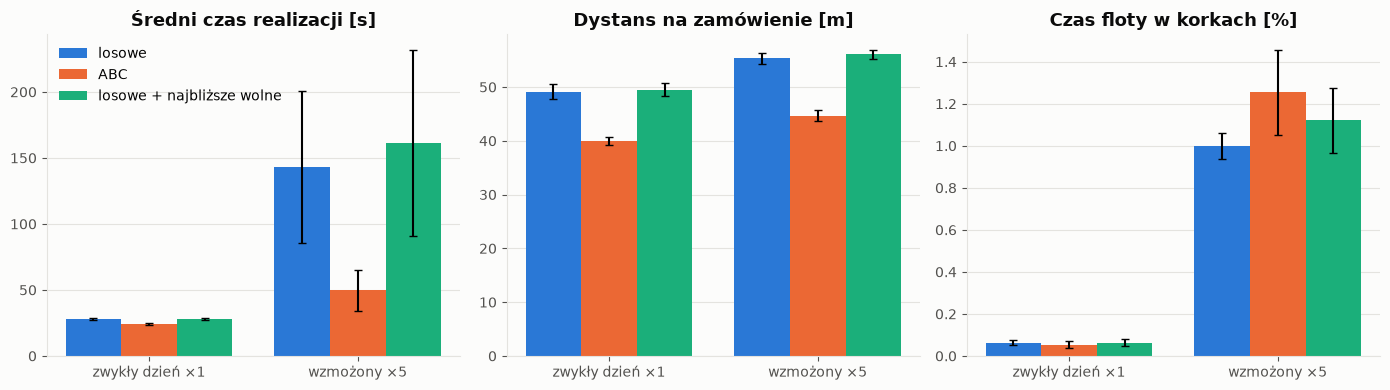

In [4]:
PLACEMENTS = {("random", "home"): "losowe", ("ABC", "home"): "ABC", ("random", "nearest"): "losowe + najbliższe wolne"}
specs = [dict(placement=p, return_policy=rp, volume=v, seed=s)
         for (p, rp) in PLACEMENTS for v in (1.0, 5.0) for s in range(1, 6)]
e1 = run_grid(specs, OUT / "e1_rozmieszczenie.csv", jobs=JOBS)
e1["wariant"] = [PLACEMENTS[(p, rp)] for p, rp in zip(e1.placement, e1.return_policy)]
METRICS = ["avg_completion_s", "max_completion_s", "distance_per_order_m", "traffic_share_pct", "racks_home_pct"]
t1 = summary(e1, ["volume", "wariant"], METRICS)

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (metric, title) in zip(axes, [("avg_completion_s", "Średni czas realizacji [s]"),
                                      ("distance_per_order_m", "Dystans na zamówienie [m]"),
                                      ("traffic_share_pct", "Czas floty w korkach [%]")]):
    bars(ax, t1, "volume", "wariant", metric)
    ax.set_title(title)
axes[0].legend()
fig.tight_layout()
fig.savefig(OUT / "e1_rozmieszczenie.png", dpi=150)

## 4. Ile robotów potrzeba (S1)

Średni czas realizacji w zależności od liczby robotów, przy wzmożonym ruchu i w Black Friday
(skala logarytmiczna).

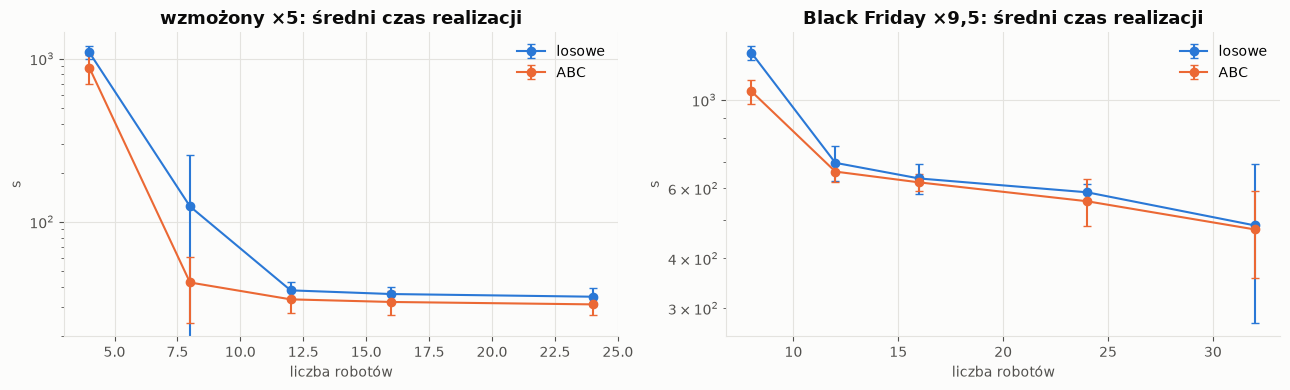

In [5]:
specs = [dict(num_robots=r, placement=p, volume=v, seed=s)
         for v, robots in ((5.0, (4, 8, 12, 16, 24)), (9.5, (8, 12, 16, 24, 32)))
         for r in robots for p in ("random", "ABC") for s in (1, 2, 3)]
e2 = run_grid(specs, OUT / "e2_roboty.csv", jobs=JOBS)
t2 = summary(e2, ["volume", "placement", "num_robots"], ["avg_completion_s", "avg_wait_for_robot_s", "station_utilisation_pct", "orders_per_hour"])

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, volume in zip(axes, (5.0, 9.5)):
    for color, placement in zip(CATEGORICAL, ("random", "ABC")):
        part = t2[(t2.volume == volume) & (t2.placement == placement)]
        ax.errorbar(part.num_robots, part.avg_completion_s, yerr=part.avg_completion_s_ci,
                    marker="o", capsize=3, color=color, label="losowe" if placement == "random" else "ABC")
    ax.set_title(f"{LOAD[volume]}: średni czas realizacji")
    ax.set_xlabel("liczba robotów")
    ax.set_ylabel("s")
    ax.set_yscale("log")
    ax.legend()
fig.tight_layout()
fig.savefig(OUT / "e2_roboty.png", dpi=150)

## 5. Przydział zadań (S6): najbliższy robot czy termin + bateria

16 robotów, 5 seedów.

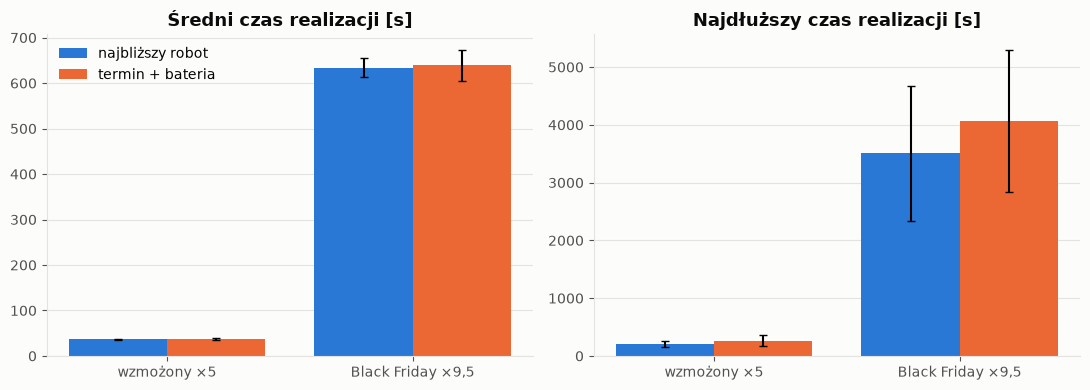

In [6]:
specs = [dict(num_robots=16, assignment=a, volume=v, seed=s)
         for a in ("nearest", "deadline_battery") for v in (5.0, 9.5) for s in range(1, 6)]
e3 = run_grid(specs, OUT / "e3_przydzial.csv", jobs=JOBS)
t3 = summary(e3, ["volume", "assignment"], ["avg_completion_s", "max_completion_s", "distance_per_order_m"])
names = {"nearest": "najbliższy robot", "deadline_battery": "termin + bateria"}

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, (metric, title) in zip(axes, [("avg_completion_s", "Średni czas realizacji [s]"),
                                      ("max_completion_s", "Najdłuższy czas realizacji [s]")]):
    bars(ax, t3, "volume", "assignment", metric, labels=names)
    ax.set_title(title)
axes[0].legend()
fig.tight_layout()
fig.savefig(OUT / "e3_przydzial.png", dpi=150)

## 6. Układy magazynu (dodatkowo)

Ten sam strumień zamówień (×5), ABC, 8 robotów, 3 seedy. Hale różnią się liczbą regałów i stanowisk,
więc to porównanie całej geometrii, a nie jednej zmiennej.

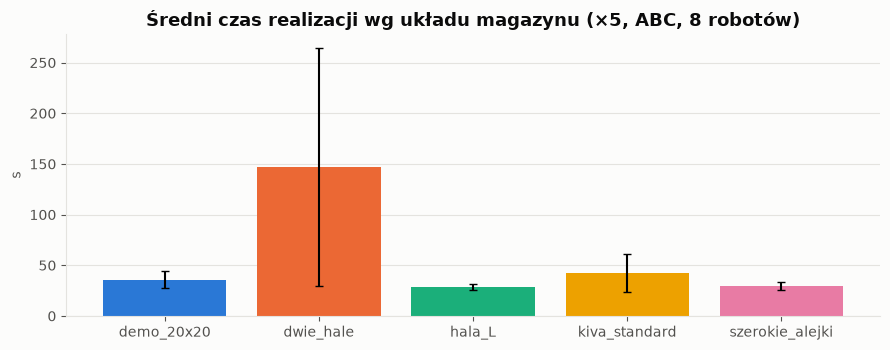

In [7]:
specs = [dict(layout=key, placement="ABC", volume=5.0, seed=s) for key in LAYOUTS for s in (1, 2, 3)]
e4 = run_grid(specs, OUT / "e4_uklady.csv", jobs=JOBS)
t4 = summary(e4, ["layout"], ["avg_completion_s", "distance_per_order_m", "traffic_share_pct", "station_utilisation_pct"])

fig, ax = plt.subplots(figsize=(9, 3.6))
ax.bar(t4.layout, t4.avg_completion_s, yerr=t4.avg_completion_s_ci, capsize=3, color=CATEGORICAL[: len(t4)])
ax.set_ylabel("s")
ax.set_title("Średni czas realizacji wg układu magazynu (×5, ABC, 8 robotów)")
ax.grid(axis="x", visible=False)
fig.tight_layout()
fig.savefig(OUT / "e4_uklady.png", dpi=150)

## 7. Czy reguły ruchu się opłacają?

Każdą regułę wyłączamy osobno, resztę zostawiamy. Lewy wykres: czy magazyn staje (zakleszczenie).
Prawy: średni czas realizacji przy ×5, tylko z przebiegów, które się nie zakleszczyły.

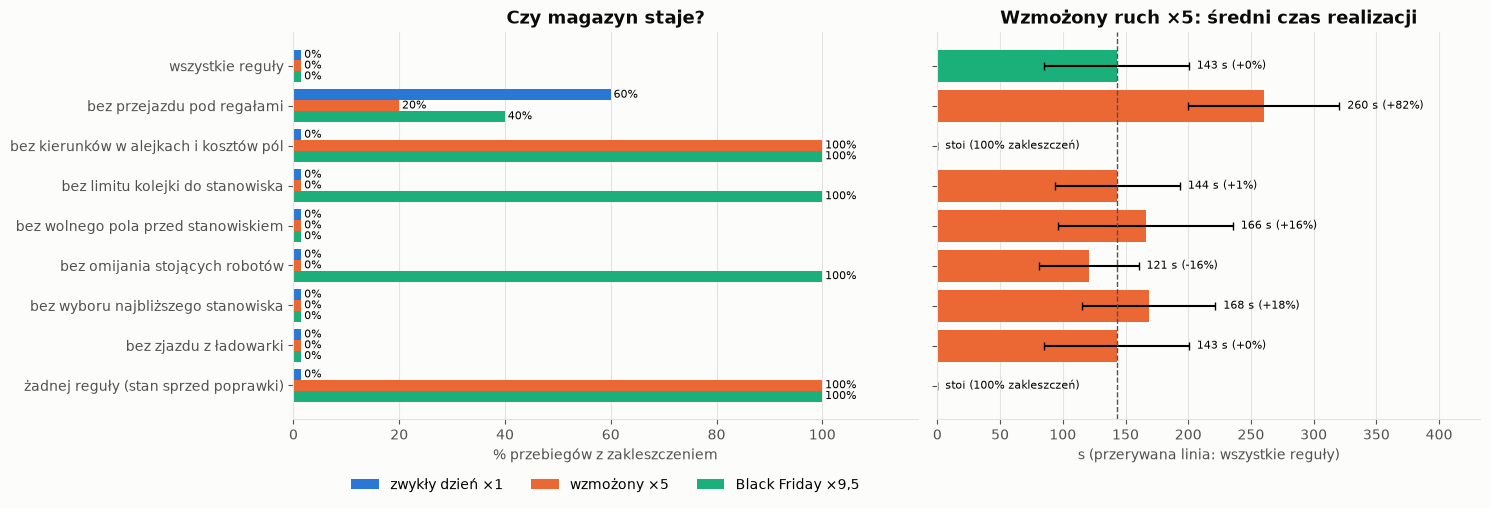

In [8]:
RULES = {
    "new": "wszystkie reguły",
    "no_under_racks": "bez przejazdu pod regałami",
    "no_route_costs": "bez kierunków w alejkach i kosztów pól",
    "no_queue_limit": "bez limitu kolejki do stanowiska",
    "no_front_free": "bez wolnego pola przed stanowiskiem",
    "no_replan": "bez omijania stojących robotów",
    "no_nearest_station": "bez wyboru najbliższego stanowiska",
    "no_leave_charger": "bez zjazdu z ładowarki",
    "old": "żadnej reguły (stan sprzed poprawki)",
}
specs = [dict(num_robots=r, volume=v, seed=s, traffic=t)
         for t in RULES for (r, v) in ((8, 1.0), (8, 5.0), (16, 9.5)) for s in range(1, 6)]
e5 = run_grid(specs, OUT / "e5_reguly.csv", jobs=JOBS)
e5["zakleszczenie"] = e5["status"].isin(["deadlock", "livelock"])
dl5 = e5.groupby(["traffic", "volume"])["zakleszczenie"].mean().mul(100).unstack(1).reindex(list(RULES))
t5 = summary(e5, ["volume", "traffic"], ["avg_completion_s", "max_completion_s", "distance_per_order_m",
                                          "avg_station_queue_s", "traffic_share_pct"])

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.15, 1]})
y = np.arange(len(RULES))
labels = [RULES[k] for k in RULES]
for i, v in enumerate((1.0, 5.0, 9.5)):
    drawn = ax1.barh(y + (i - 1) * 0.27, dl5[v].clip(lower=1.5), 0.27, color=CATEGORICAL[i], label=LOAD[v])
    ax1.bar_label(drawn, labels=[f"{x:.0f}%" for x in dl5[v]], padding=2, fontsize=8)
ax1.set_yticks(y, labels)
ax1.invert_yaxis()
ax1.set_xlim(0, 118)
ax1.set_xlabel("% przebiegów z zakleszczeniem")
ax1.set_title("Czy magazyn staje?")
ax1.grid(axis="y", visible=False)
ax1.legend(loc="upper center", bbox_to_anchor=(0.5, -0.12), ncol=3)

part = t5[t5.volume == 5.0].set_index("traffic").reindex(list(RULES))
base = part.loc["new", "avg_completion_s"]
ax2.barh(y, part.avg_completion_s.fillna(0), xerr=part.avg_completion_s_ci.fillna(0), capsize=3,
         color=[CATEGORICAL[2] if k == "new" else CATEGORICAL[1] for k in RULES])
ax2.axvline(base, color=INK_SECONDARY, lw=1, ls="--")
for yy, k in zip(y, RULES):
    value, ci = part.loc[k, "avg_completion_s"], part.loc[k, "avg_completion_s_ci"]
    text = "stoi (100% zakleszczeń)" if pd.isna(value) else f"{value:.0f} s ({100 * (value - base) / base:+.0f}%)"
    # Podpis za końcem paska błędu, żeby się nie nakładały.
    ax2.text(0 if pd.isna(value) else value + (0 if pd.isna(ci) else ci), yy, "  " + text, va="center", fontsize=8)
ax2.set_yticks(y, [""] * len(y))
ax2.invert_yaxis()
ax2.set_xlim(0, (part.avg_completion_s + part.avg_completion_s_ci.fillna(0)).max() * 1.35)
ax2.set_xlabel("s (przerywana linia: wszystkie reguły)")
ax2.set_title("Wzmożony ruch ×5: średni czas realizacji")
ax2.grid(axis="y", visible=False)
fig.tight_layout()
fig.savefig(OUT / "e5_reguly.png", dpi=150)


**Co z tego wynika** (5 seedów, 4 h; liczby z tabeli powyżej):

* **Przejazd pod regałami jest potrzebny niezależnie od natężenia.** Bez niego zakleszcza się
  nawet zwykły dzień (60% przebiegów przy ×1), a gdy magazyn nie stanie, dystans na zamówienie rośnie
  o ok. 14–16%, a średni czas realizacji o ok. 20% (×1) i ok. 80% (×5), bo puste roboty objeżdżają
  regały alejkami. To jedyna reguła, która ma też sens „biznesowy”: mówi, ile wart jest robot,
  który mieści się pod regałem.
* **Kierunki w alejkach (z kosztami pól) to cena za brak zakleszczeń.** Przy zwykłym dniu bez nich
  jest szybciej (dystans −18%, czas −11%), bo roboty jadą najkrótszą drogą, ale od ×5 wzwyż każdy
  przebieg staje. Przy małym ruchu reguła kosztuje, przy dużym jest konieczna.
* **Limit kolejki i omijanie stojących robotów** przy ×1 i ×5 nie zmieniają wyniku istotnie
  (różnice mieszczą się w przedziałach ufności), ale bez każdej z nich Black Friday zawsze się
  zakleszcza. To reguły „na szczyt”.
* **Wolne pole przed stanowiskiem i wybór najbliższego stanowiska** nie chronią przed
  zakleszczeniem, tylko przyspieszają: bez nich czas realizacji przy Black Friday rośnie o ok. 32%
  i 10%, przy ×5 o ok. 16–18% (przy ×5 przedziały ufności są szerokie, 5 seedów).
* **Zjazd z ładowarki** nie zmienia wyniku w tych 4-godzinnych przebiegach (wyniki są co do sekundy
  takie same, więc reguła w tym czasie nie zadziałała). Ma znaczenie dopiero w dłuższych przebiegach,
  gdy roboty kończą ładowanie; tu jej nie widać.

## 8. Najważniejsze zmiany w liczbach

In [9]:
def change(table, by, base, other, metric, **where):
    part = table
    for key, value in where.items():
        part = part[part[key] == value]
    a = part[part[by] == base][metric].iloc[0]
    b = part[part[by] == other][metric].iloc[0]
    return f"{a:.1f} → {b:.1f} ({100 * (b - a) / a:+.0f}%)"

rows = []
for v in (1.0, 5.0):
    for metric, name in [("avg_completion_s", "średni czas [s]"), ("distance_per_order_m", "dystans/zam. [m]"),
                         ("traffic_share_pct", "korki [% czasu floty]")]:
        rows.append({"porównanie": f"losowe → ABC, {LOAD[v]}", "miara": name,
                     "zmiana": change(t1, "wariant", "losowe", "ABC", metric, volume=v)})
for v in (5.0, 9.5):
    rows.append({"porównanie": f"najbliższy → termin+bateria, {LOAD[v]}", "miara": "średni czas [s]",
                 "zmiana": change(t3, "assignment", "nearest", "deadline_battery", "avg_completion_s", volume=v)})
pd.DataFrame(rows).style.hide(axis="index")

porównanie,miara,zmiana
"losowe → ABC, zwykły dzień ×1",średni czas [s],28.1 → 24.2 (-14%)
"losowe → ABC, zwykły dzień ×1",dystans/zam. [m],49.1 → 40.0 (-19%)
"losowe → ABC, zwykły dzień ×1",korki [% czasu floty],0.1 → 0.1 (-15%)
"losowe → ABC, wzmożony ×5",średni czas [s],142.9 → 49.7 (-65%)
"losowe → ABC, wzmożony ×5",dystans/zam. [m],55.3 → 44.7 (-19%)
"losowe → ABC, wzmożony ×5",korki [% czasu floty],1.0 → 1.3 (+26%)
"najbliższy → termin+bateria, wzmożony ×5",średni czas [s],36.2 → 36.9 (+2%)
"najbliższy → termin+bateria, Black Friday ×9,5",średni czas [s],633.7 → 639.6 (+1%)


## 9. Kalibracja i walidacja

### 9.1 Parametry robota: skąd liczby

| Parametr | W modelu | Źródło | Pewność |
| --- | --- | --- | --- |
| prędkość | 1,3 m/s | IEEE Spectrum 2008, karta robota IEEE 2018, MWPVL 2012 | wysoka: 3 niezależne źródła |
| pole siatki | 1 m | IEEE Spectrum (kody na podłodze co 1 m), MWPVL (regał 39″), Wurman i in. 2007 | wysoka |
| kompletacja | 6 s na sztukę (600 linii/h) | Wurman i in. 2007 (twórcy Kiva), IEEE Spectrum, MWPVL | wysoka |
| bateria | ok. 2 h jazdy (0,0107% na metr) | MWPVL: ładowanie „co kilka godzin” | niska: jedno źródło |
| ładowanie | 5 min, od 20% do pełna | MWPVL: „5-minutowe doładowanie”; próg 20% to założenie modelu | średnia |

Źródła nie podają przyspieszenia ani czasu obrotu i podnoszenia regału, więc tego nie modelujemy.
Niepewne parametry sprawdza scenariusz S5: prędkość 1,0 / 1,5 m/s, kompletacja 200–700 linii/h,
bateria 1 / 4 h. Cytaty i przeliczenia: `docs/zrodla_parametry_robota.md`.

### 9.2 Dane zamówień (Olist)

Generator skalibrowany na zamówieniach z 2017 losuje tyle dni, ile obejmują dane z 2018, i porównujemy
udziały z prawdziwymi zamówieniami z 2018. Porównanie jest zgodne, gdy żaden udział nie różni się
o więcej niż 2 punkty procentowe.

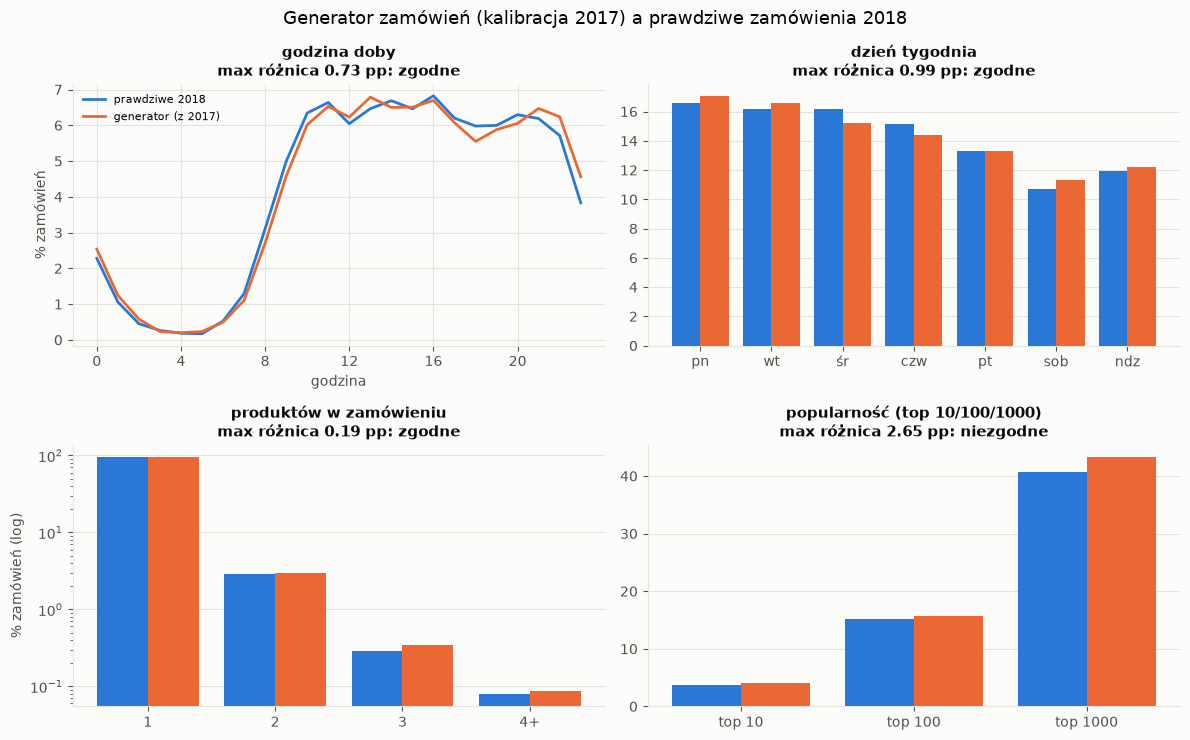

porównanie,"największa różnica [pp], próg 2",wynik
godzina doby,0.73,zgodne
dzień tygodnia,0.99,zgodne
produktów w zamówieniu,0.19,zgodne
sztuk w pozycji,0.17,zgodne
popularność (top 10/100/1000),2.65,NIEZGODNE


In [10]:
from runners.olist_validation import (
    CALIBRATION_YEAR, SEED, THRESHOLD_PP, VALIDATION_YEAR, concentration, order_share_by, orders_to_table,
)
from src.data import olist
from src.orders.olist_generator import generate_orders
from src.plotting.style import GENERATED, REAL

orders_all = olist.load_orders()
real = olist.year(orders_all, VALIDATION_YEAR)
real_days = olist.daily_counts(real)
start = real_days.index.min()
calibrated = olist.compute_stats(olist.year(orders_all, CALIBRATION_YEAR))
generated = orders_to_table(
    generate_orders(calibrated, np.random.default_rng(SEED), start, len(real_days) * 86400.0), start
)


def shares(table):
    """The five compared distributions, in percent."""
    items = olist.items_per_order(table)
    return {
        "godzina doby": order_share_by(table, "hour") * 100,
        "dzień tygodnia": order_share_by(table, "weekday") * 100,
        "produktów w zamówieniu": items * 100,
        "sztuk w pozycji": olist.quantity_per_line(table) * 100,
        "popularność (top 10/100/1000)": concentration(table) * 100,
    }


r, g = shares(real), shares(generated)
worst = {name: g[name].sub(r[name], fill_value=0).abs().max() for name in r}


def four_plus(share):
    return pd.Series({"1": share.get(1, 0.0), "2": share.get(2, 0.0), "3": share.get(3, 0.0),
                      "4+": share[share.index >= 4].sum()})

fig, axes = plt.subplots(2, 2, figsize=(12, 7.5))
axes = axes.ravel()
real_label, gen_label = f"prawdziwe {VALIDATION_YEAR}", f"generator (z {CALIBRATION_YEAR})"
ax = axes[0]
ax.plot(r["godzina doby"].index, r["godzina doby"], color=REAL, lw=2, label=real_label)
ax.plot(g["godzina doby"].index, g["godzina doby"], color=GENERATED, lw=2, label=gen_label)
ax.set_xticks(range(0, 24, 4))
ax.set_xlabel("godzina")
ax.set_ylabel("% zamówień")
ax.legend(fontsize=8)
for ax, name, labels in [
    (axes[1], "dzień tygodnia", ["pn", "wt", "śr", "czw", "pt", "sob", "ndz"]),
    (axes[2], "produktów w zamówieniu", None),
    (axes[3], "popularność (top 10/100/1000)", None),
]:
    rr, gg = (four_plus(r[name]), four_plus(g[name])) if name == "produktów w zamówieniu" else (r[name], g[name])
    gg = gg.reindex(rr.index, fill_value=0)
    x = np.arange(len(rr))
    ax.bar(x - 0.2, rr, 0.4, color=REAL, label=real_label)
    ax.bar(x + 0.2, gg, 0.4, color=GENERATED, label=gen_label)
    ax.set_xticks(x, labels or [str(i) for i in rr.index])
    ax.grid(axis="x", visible=False)
axes[2].set_yscale("log")
axes[2].set_ylabel("% zamówień (log)")
for ax, name in zip(axes, ["godzina doby", "dzień tygodnia", "produktów w zamówieniu",
                           "popularność (top 10/100/1000)"]):
    mark = "zgodne" if worst[name] <= THRESHOLD_PP else "niezgodne"
    ax.set_title(f"{name}\nmax różnica {worst[name]:.2f} pp: {mark}", fontsize=11)
fig.suptitle(f"Generator zamówień (kalibracja {CALIBRATION_YEAR}) a prawdziwe zamówienia {VALIDATION_YEAR}",
             fontsize=13)
fig.tight_layout()
plt.show()

pd.DataFrame(
    [(name, round(value, 2), "zgodne" if value <= THRESHOLD_PP else "NIEZGODNE") for name, value in worst.items()],
    columns=["porównanie", f"największa różnica [pp], próg {THRESHOLD_PP:g}", "wynik"],
).style.hide(axis="index").format(precision=2)

**4 z 5 porównań zgodnych.** Popularność odstaje o 2,65 pp przy top 1000 produktów: generator
trochę za często losuje popularne produkty. Liczba zamówień w 2018 była 1,77× większa niż w 2017;
skalę ruchu ustawiamy osobno (×1, ×5, ×9,5), więc nie porównujemy jej z generatorem.

### 9.3 Teoria kolejek, część A: samo stanowisko

Samo stanowisko bez magazynu: roboty przyjeżdżają w losowych chwilach (proces Poissona), obsługa
trwa średnio 15 s i jest stała albo wykładnicza. Wtedy spełnione są założenia wzoru M/G/1
(Pollaczka–Chinczyna), więc symulacja musi się z nim zgadzać. Ten sam przypadek sprawdza test
`tests/test_queueing.py`.

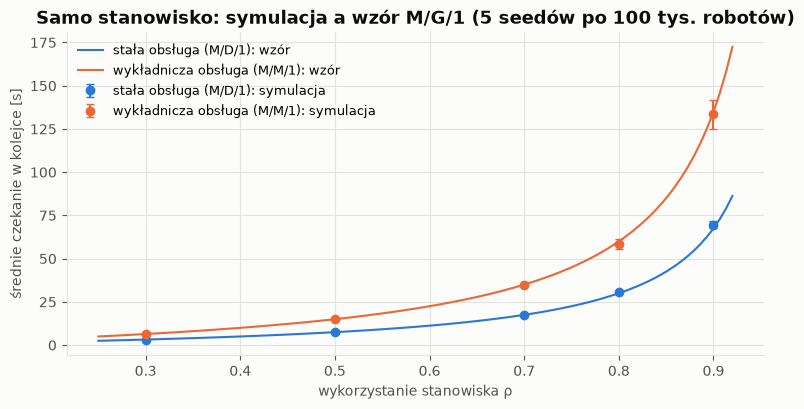

Największa różnica symulacji od wzoru: 3.2% (stała obsługa (M/D/1), ρ = 0.9)


In [11]:
import importlib.util

from src.core.config import PickingParams
from src.validation.queueing import arrival_rate_for, confidence_interval, mg1_wait, service_moments

# The station-only model lives in the test of part A; reuse it as it is.
spec = importlib.util.spec_from_file_location("test_queueing", ROOT / "tests" / "test_queueing.py")
station_test = importlib.util.module_from_spec(spec)
spec.loader.exec_module(station_test)

SERVICE = {"deterministic": "stała obsługa (M/D/1)", "exponential": "wykładnicza obsługa (M/M/1)"}
RHOS = (0.3, 0.5, 0.7, 0.8, 0.9)
QA = OUT / "e6_kolejka_stanowisko.csv"
if QA.exists():
    qa = pd.read_csv(QA)
else:  # 50 runs x 100 000 robots, ok. 1,5 min
    rows = []
    for distribution in SERVICE:
        picking = PickingParams(fixed_s=5.0, per_item_s=10.0, distribution=distribution)
        for rho in RHOS:
            for seed in range(5):
                model = station_test.StationOnlyModel(picking, rho, rng=seed)
                model.run_for(10**9)
                rows.append(dict(distribution=distribution, rho=rho, seed=seed, wait=model.mean_wait()))
    qa = pd.DataFrame(rows)
    qa.to_csv(QA, index=False)


def formula(distribution, rho):
    mean_s, second = service_moments(PickingParams(5.0, 10.0, distribution), items=1)
    return mg1_wait(arrival_rate_for(rho, mean_s), mean_s, second)


fig, ax = plt.subplots(figsize=(9, 4.2))
grid = np.linspace(0.25, 0.92, 100)
errors = []
for (distribution, label), color in zip(SERVICE.items(), CATEGORICAL):
    ax.plot(grid, [formula(distribution, x) for x in grid], color=color, lw=1.5, label=f"{label}: wzór")
    for rho, part in qa[qa.distribution == distribution].groupby("rho"):
        centre, half = confidence_interval(list(part["wait"]))
        ax.errorbar(rho, centre, yerr=half, fmt="o", color=color, ms=6, capsize=3,
                    label=f"{label}: symulacja" if rho == RHOS[0] else None)
        errors.append((abs(centre - formula(distribution, rho)) / formula(distribution, rho) * 100, rho, label))
ax.set_xlabel("wykorzystanie stanowiska ρ")
ax.set_ylabel("średnie czekanie w kolejce [s]")
ax.set_title("Samo stanowisko: symulacja a wzór M/G/1 (5 seedów po 100 tys. robotów)")
ax.legend(fontsize=9)
plt.show()
gap, gap_rho, gap_label = max(errors)
print(f"Największa różnica symulacji od wzoru: {gap:.1f}% ({gap_label}, ρ = {gap_rho:g})")

Symulacja stanowiska zgadza się ze wzorem w całym zakresie obciążenia, więc sama kolejka i pomiar
czekania działają poprawnie.

### 9.4 Teoria kolejek, część B: cały magazyn

Cały magazyn z jednym stanowiskiem i 40 robotami (`runners/queue_validation.py`, 160 przebiegów,
ok. 11 min). Zamówienia przychodzą jak w części A, ale do stanowiska docierają roboty, które musiały
dojechać po regał. Wynik z 23.11:

In [12]:
validation = pd.DataFrame(
    [
        ("stała", 0.3, 3.2, 5.1, 0.3, 0.30, 0.8, "20/20", "NOT OK"),
        ("stała", 0.5, 7.5, 11.3, 0.3, 0.50, 1.1, "20/20", "NOT OK"),
        ("stała", 0.7, 17.5, 20.9, 0.5, 0.70, 8.0, "20/20", "NOT OK"),
        ("stała", 0.9, 67.5, 26.2, 0.1, 0.78, 417.4, "20/20", "LIMIT"),
        ("wykładnicza", 0.3, 6.4, 7.7, 0.8, 0.30, 0.8, "20/20", "NOT OK"),
        ("wykładnicza", 0.5, 15.0, 14.1, 0.8, 0.50, 1.7, "20/20", "NOT OK"),
        ("wykładnicza", 0.7, 35.0, 22.2, 0.4, 0.70, 18.8, "20/20", "NOT OK"),
        ("wykładnicza", 0.9, 135.0, 25.8, 0.2, 0.78, 585.3, "19/20", "LIMIT"),
    ],
    columns=["obsługa", "ρ", "wzór M/G/1 [s]", "symulacja [s]", "± 95%", "ρ zmierzone",
             "czekanie na robota [s]", "udane", "wynik"],
)
validation.style.hide(axis="index").format(precision=1).format("{:.2f}", subset=["ρ zmierzone"])

obsługa,ρ,wzór M/G/1 [s],symulacja [s],± 95%,ρ zmierzone,czekanie na robota [s],udane,wynik
stała,0.3,3.2,5.1,0.3,0.30,0.8,20/20,NOT OK
stała,0.5,7.5,11.3,0.3,0.50,1.1,20/20,NOT OK
stała,0.7,17.5,20.9,0.5,0.70,8.0,20/20,NOT OK
stała,0.9,67.5,26.2,0.1,0.78,417.4,20/20,LIMIT
wykładnicza,0.3,6.4,7.7,0.8,0.30,0.8,20/20,NOT OK
wykładnicza,0.5,15.0,14.1,0.8,0.50,1.7,20/20,NOT OK
wykładnicza,0.7,35.0,22.2,0.4,0.70,18.8,20/20,NOT OK
wykładnicza,0.9,135.0,25.8,0.2,0.78,585.3,19/20,LIMIT


**Dlaczego cały magazyn nie zgadza się ze wzorem** (to skutek reguł ruchu, nie błąd kolejki):
- **Przekazanie stanowiska.** Następny robot czeka pole przed stanowiskiem, więc po każdej obsłudze
  stanowisko chwilę stoi. Nawet przy ρ = 0,3 kolejka trwa 5,1 s zamiast 3,2 s.
- **Limit 3 robotów** liczy też roboty jadące z daleka. Przy ρ = 0,9 stanowisko pracuje tylko 78%
  czasu, a zamówienia czekają na robota 7–10 min (kod `LIMIT`: wzór nie opisuje takiego układu).

**Do decyzji (pytanie do prowadzącego):**
- **A)** Walidacją z teorią kolejek jest samo stanowisko (9.3), a cały magazyn pokazujemy jako koszt reguł ruchu.
- **B)** Limit liczy tylko roboty blisko stanowiska. Powinno to też przyspieszyć Black Friday
  (stanowiska zajęte tylko ok. 50% czasu), ale trzeba od nowa sprawdzić zakleszczenia.
- **C)** Do wzoru doliczamy zmierzony czas przekazania stanowiska. Pomaga przy małym ruchu, nie przy ρ = 0,9.

## 10. Wnioski i co dalej

**Wnioski z przykładowych wyników**
- ABC zamiast losowego rozmieszczenia skraca dystans i czas realizacji; przy dużym ruchu zysk jest największy.
- Odstawianie regału na najbliższe wolne miejsce praktycznie nic nie daje.
- Od ok. 12 robotów dokładanie kolejnych pomaga coraz mniej; w szczycie wąskim gardłem jest dojazd do stanowiska.
- „Termin + bateria” nie różni się od „najbliższego robota”, bo terminy Olist to dni, a przebieg trwa godziny.
- Przejazd pustych robotów pod regałami jest potrzebny: bez niego magazyn staje nawet w zwykły dzień.

**Co dalej**
1. Pełne liczenie scenariuszy (całe doby, 10+ seedów), z odróżnieniem zakleszczenia od przeciążenia.
2. Scenariusz S4 (awarie a pilne zamówienia): potrzebna definicja „pilnego” zamówienia.
3. Decyzja A/B/C w walidacji (ewentualnie zmiana limitu przy stanowisku).
4. Sprawozdanie w szablonie LaTeX.

**Pytania do prowadzącego**
- Która opcja walidacji (A, B, C) będzie wystarczająca?
- Jak zdefiniować pilne zamówienia, skoro w danych terminy wysyłki to dni?
- Czy porównanie układów magazynu (spoza tematu) włączyć do wyników?

## Dodatek A. Scenariusze z opisu projektu: stan na 23.11

| Scenariusz | Co sprawdza | Stan |
| --- | --- | --- |
| S1 | liczba robotów × rozmieszczenie (losowe, ABC, najbliższe wolne) | **częściowo:** przykładowe wyniki (sekcje 3–4); całe doby do policzenia |
| S2 | zwykły dzień i szczyt | **częściowo:** ×1, ×5 i Black Friday ×9,5 w sekcjach 2 i 4; cała doba w szczycie przeciąża układ standardowy |
| S3 | liczba stanowisk i ładowarek (1–4) | **gotowy do liczenia:** zdefiniowany w runnerze, bez wyników |
| S4 | awarie a pilne zamówienia | **wstrzymany:** awarie są w modelu, brakuje definicji pilnego zamówienia |
| S5 | wrażliwość: prędkość, kompletacja, bateria | **gotowy do liczenia:** zdefiniowany w runnerze, bez wyników |
| S6 | przydział: najbliższy robot albo termin + bateria | **częściowo:** przykładowe wyniki (sekcja 5) |
| walidacja | dane Olist, teoria kolejek | **zrobiona:** Olist 4 z 5, samo stanowisko zgodne; cały magazyn do decyzji A/B/C |
| opcjonalnie | agent uczony na symulacji do przydziału zadań | **niezaczęty** |

## Dodatek B. Przepływ zamówienia w modelu

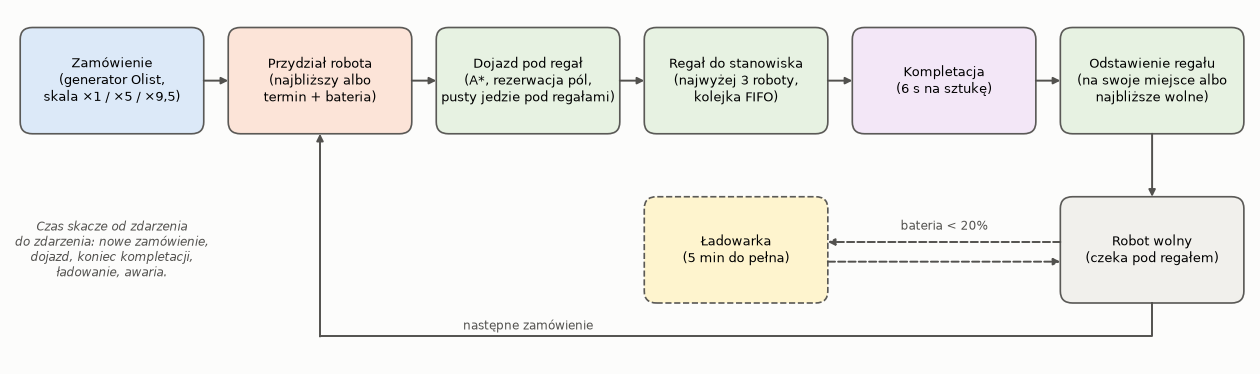

In [13]:
from matplotlib.patches import FancyBboxPatch

fig, ax = plt.subplots(figsize=(16, 4.6))
ax.set_xlim(0, 15.2)
ax.set_ylim(-1.0, 3.5)
ax.axis("off")
W, H = 2.15, 1.25


def box(x, y, text, color, dashed=False):
    ax.add_patch(FancyBboxPatch((x - W / 2, y - H / 2), W, H, boxstyle="round,pad=0.05,rounding_size=0.15",
                                fc=color, ec=INK_SECONDARY, lw=1.2, ls="--" if dashed else "-", alpha=0.95))
    ax.text(x, y, text, ha="center", va="center", fontsize=9.5)


def arrow(start, end, text=None, dashed=False):
    ax.annotate("", end, start, arrowprops=dict(arrowstyle="-|>", color=INK_SECONDARY, lw=1.4,
                                                 ls="--" if dashed else "-", shrinkA=0, shrinkB=0))
    if text:
        ax.text((start[0] + end[0]) / 2, (start[1] + end[1]) / 2 + 0.12, text, ha="center",
                va="bottom", fontsize=8.5, color=INK_SECONDARY)


steps = [
    "Zamówienie\n(generator Olist,\nskala ×1 / ×5 / ×9,5)",
    "Przydział robota\n(najbliższy albo\ntermin + bateria)",
    "Dojazd pod regał\n(A*, rezerwacja pól,\npusty jedzie pod regałami)",
    "Regał do stanowiska\n(najwyżej 3 roboty,\nkolejka FIFO)",
    "Kompletacja\n(6 s na sztukę)",
    "Odstawienie regału\n(na swoje miejsce albo\nnajbliższe wolne)",
]
colors = ["#dbe8f8", "#fde3d6", "#e6f2e1", "#e6f2e1", "#f3e6f7", "#e6f2e1"]
xs = [1.25 + i * 2.55 for i in range(len(steps))]
for x, text, color in zip(xs, steps, colors):
    box(x, 2.6, text, color)
for a, b in zip(xs, xs[1:]):
    arrow((a + W / 2 + 0.05, 2.6), (b - W / 2 - 0.05, 2.6))

box(xs[5], 0.45, "Robot wolny\n(czeka pod regałem)", "#f1f0ec")
box(xs[3], 0.45, "Ładowarka\n(5 min do pełna)", "#fff4cc", dashed=True)
arrow((xs[5], 2.6 - H / 2 - 0.05), (xs[5], 0.45 + H / 2 + 0.05))
arrow((xs[5] - W / 2 - 0.05, 0.55), (xs[3] + W / 2 + 0.05, 0.55), "bateria < 20%", dashed=True)
arrow((xs[3] + W / 2 + 0.05, 0.3), (xs[5] - W / 2 - 0.05, 0.3), dashed=True)
ax.plot([xs[5], xs[5], xs[1]], [0.45 - H / 2 - 0.05, -0.65, -0.65], color=INK_SECONDARY, lw=1.4)
arrow((xs[1], -0.65), (xs[1], 2.6 - H / 2 - 0.05))
ax.text((xs[1] + xs[3]) / 2, -0.6, "następne zamówienie", ha="center", va="bottom", fontsize=8.5,
        color=INK_SECONDARY)
ax.text(xs[0], 0.45, "Czas skacze od zdarzenia\ndo zdarzenia: nowe zamówienie,\ndojazd, koniec kompletacji,\n"
        "ładowanie, awaria.", ha="center", va="center", fontsize=8.5, color=INK_SECONDARY, style="italic")
plt.show()